# 05 — Is the NS1/NS2 CpG loss in RSV-A a synonymous-site effect?

---

### Where we are

The one clear result so far: **RSV-A NS1 and NS2 have far fewer CpGs than RSV-B** (CpG O/E 0.016 vs 0.204 in NS1, 0.072 vs 0.517 in NS2) while their GC content is the same. Over time nothing moves; this is a fixed difference between the two subtypes.

### The questions here

1. **Host.** Does the data hold any host other than human?
2. **Where in the codon is the CpG missing?** A CpG shortage that sits where the protein is free to change (synonymous codon choices) points to pressure on the RNA. A shortage where the amino acid fixes the bases would instead point to the protein.
3. **Is the protein under different selection in A and B?** (HyPhy dN/dS)
4. **Does it change over time inside a lineage?**

> **How to read the codon classes.** CpG can sit in three places relative to the codon boundary:
> - **12**: C is codon position 1, G is position 2 (Arg `CGN`). The amino acid fixes it.
> - **23**: C at 2, G at 3 (`CCG` Pro, `GCG` Ala, `ACG` Thr, `TCG` Ser). The G is free: any base at position 3 gives the same amino acid.
> - **31**: C at position 3 of one codon, G at position 1 of the next. The C is usually free; the G is set by the next amino acid.


In [1]:
import sys, os
sys.path.insert(0, os.path.abspath("../src"))
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from rsv import codon, genes

ROOT = os.path.abspath("..")
os.chdir(ROOT)                      # paths below are relative to the repo root
pd.set_option("display.width", 130)
plt.rcParams.update({"figure.dpi": 110, "font.size": 9,
                     "axes.spines.top": False, "axes.spines.right": False})
PAL = {"A": "#2C7FB8", "B": "#C62824"}
GENES = ["NS1", "NS2", "N", "P", "M", "SH", "G", "F", "M2-1", "L"]


---
## 5.1 Host

GISAID's `Host` field, over all downloaded genomes.

In [2]:
meta = pd.read_csv("data/full/RSV_full_metadata.tsv", sep="\t", dtype=str)
print(meta["Host"].value_counts(dropna=False).to_string())
print("\nExtra host notes (non-empty):", meta["Additional host information"].notna().sum(),
      "- all clinical (co-infections, study names); none name a non-human host")

Host
Human    33040

Extra host notes (non-empty): 312 - all clinical (co-infections, study names); none name a non-human host


Every genome is `Human`. RSV cannot be split by host, so the sporadic-versus-sustained idea needs a different virus (Track 2).

---
## 5.2 The codon data

Genomes were re-drawn from the same 9 lineages used in the trend analysis, at most **250 per lineage**, so no single lineage dominates. Each gene was cut out, kept only if it starts with ATG and is in frame to its first stop (`scripts/build_codon_data.py`).

In [3]:
smp = pd.read_csv("data/processed/cds/sample.tsv", sep="\t")
fr = pd.read_csv("data/processed/cds/frame_report.tsv", sep="\t")
print(smp.groupby(["Subtype", "lineage_grp"]).size().rename("genomes").to_frame().T.to_string())
print()
print(fr.pivot(index="gene", columns="Subtype", values="kept").reindex(GENES).T.to_string())

Subtype        A                                  B            
lineage_grp  A.D A.D.1 A.D.2 A.D.3 A.D.4 A.D.5  B.D B.D.4 B.D.E
genomes      250   250   250   250   250   250  250   250   250

gene      NS1   NS2     N     P     M    SH     G     F  M2-1     L
Subtype                                                            
A        1460  1490  1496  1492  1492  1498  1487  1483  1494  1459
B         718   741   748   749   746   740   737   746   749   735


---
## 5.3 Codon statistics per lineage

For every lineage and gene: GC at the third codon position, the effective number of codons (ENC: 20 means each amino acid uses one codon only, 61 means every codon is used equally), and CpG O/E in each of the three classes. Counts are pooled across a lineage's genomes before the ratio is taken. **Each lineage is one data point**, so the comparison is 6 RSV-A lineages against 3 RSV-B (genomes inside a lineage are not independent).

In [4]:
lin = dict(zip(smp["Accession ID"], smp["lineage_grp"]))
rows = []
for sub in "AB":
    for g in GENES:
        d = genes.read_fasta(f"data/processed/cds/{sub}_{g}.fasta")
        by = {}
        for acc, s in d.items():
            by.setdefault(lin[acc], []).append(s)
        for l, ss in by.items():
            t = codon.tally(ss)
            oe, ob = codon.cpg_oe(t)
            cg, ng, co, no = codon.junction_c3_rates(ss)
            rows.append(dict(Subtype=sub, lineage=l, gene=g, n=len(ss), gc3=codon.gc3(t),
                             enc=codon.enc(t), oe12=oe["12"], oe23=oe["23"], oe31=oe["31"],
                             cpg12=ob["12"], cpg23=ob["23"], cpg31=ob["31"],
                             c3_before_G=cg / ng, c3_before_other=co / no))
lin_tab = pd.DataFrame(rows)
lin_tab["junction_ratio"] = lin_tab["c3_before_G"] / lin_tab["c3_before_other"]
lin_tab.to_csv("results/codon_by_lineage.tsv", sep="\t", index=False)
print(len(lin_tab), "lineage x gene rows -> results/codon_by_lineage.tsv")

def span(col, genes_=GENES):
    """Range of lineage values per gene and subtype, as 'min-max'."""
    g = lin_tab.groupby(["gene", "Subtype"])[col].agg(["min", "max"]).round(2)
    s = (g["min"].astype(str) + "-" + g["max"].astype(str)).unstack()
    return s.reindex(genes_)

90 lineage x gene rows -> results/codon_by_lineage.tsv


### GC3 and ENC: is codon choice generally different between A and B?

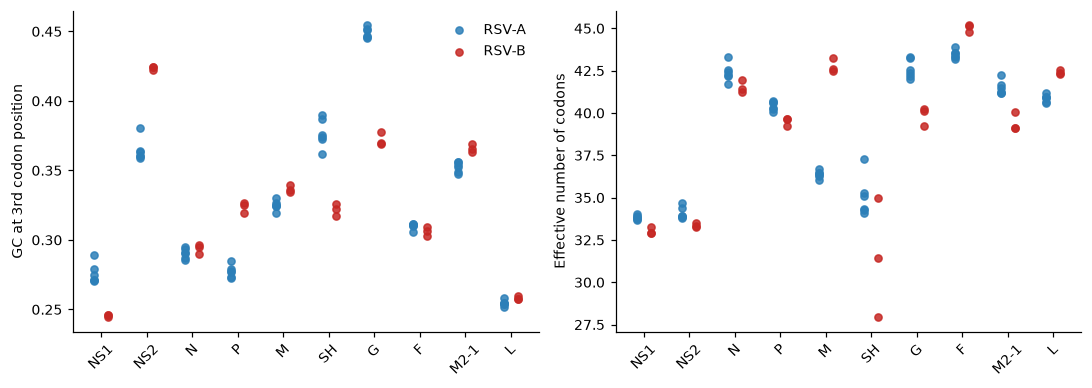

Subtype,A GC3,B GC3,A ENC,B ENC
gene,,,,
NS1,0.27-0.29,0.24-0.25,33.69-34.06,32.89-33.26
NS2,0.36-0.38,0.42-0.42,33.81-34.66,33.27-33.52
N,0.29-0.29,0.29-0.3,41.74-43.29,41.26-41.98
P,0.27-0.28,0.32-0.33,40.07-40.72,39.25-39.68
M,0.32-0.33,0.33-0.34,36.07-36.72,42.51-43.27
SH,0.36-0.39,0.32-0.33,34.12-37.28,27.94-34.99
G,0.45-0.45,0.37-0.38,42.03-43.3,39.21-40.24
F,0.31-0.31,0.3-0.31,43.18-43.92,44.79-45.18
M2-1,0.35-0.36,0.36-0.37,41.16-42.23,39.11-40.08


In [5]:
fig, axs = plt.subplots(1, 2, figsize=(10, 3.6))
for ax, col, lab in zip(axs, ["gc3", "enc"], ["GC at 3rd codon position", "Effective number of codons"]):
    for i, g in enumerate(GENES):
        for sub, off in (("A", -0.15), ("B", 0.15)):
            v = lin_tab[(lin_tab.gene == g) & (lin_tab.Subtype == sub)][col]
            ax.scatter(np.full(len(v), i + off), v, s=22, color=PAL[sub], alpha=.85, label=f"RSV-{sub}" if i == 0 else None)
    ax.set_xticks(range(len(GENES))); ax.set_xticklabels(GENES, rotation=45); ax.set_ylabel(lab)
axs[0].legend(frameon=False)
plt.tight_layout(); plt.show()
span("gc3").join(span("enc"), lsuffix=" GC3", rsuffix=" ENC")

**Reading it.** GC3 and ENC are alike in A and B for NS1 (GC3 0.27-0.29 vs 0.24-0.25; ENC about 33-34 in both), and mostly alike elsewhere. So RSV-A does not use a generally different codon style in NS1; the difference is specific to CpG. (M's ENC differs, 36 vs 43, but its CpG does not.)

### CpG by codon position

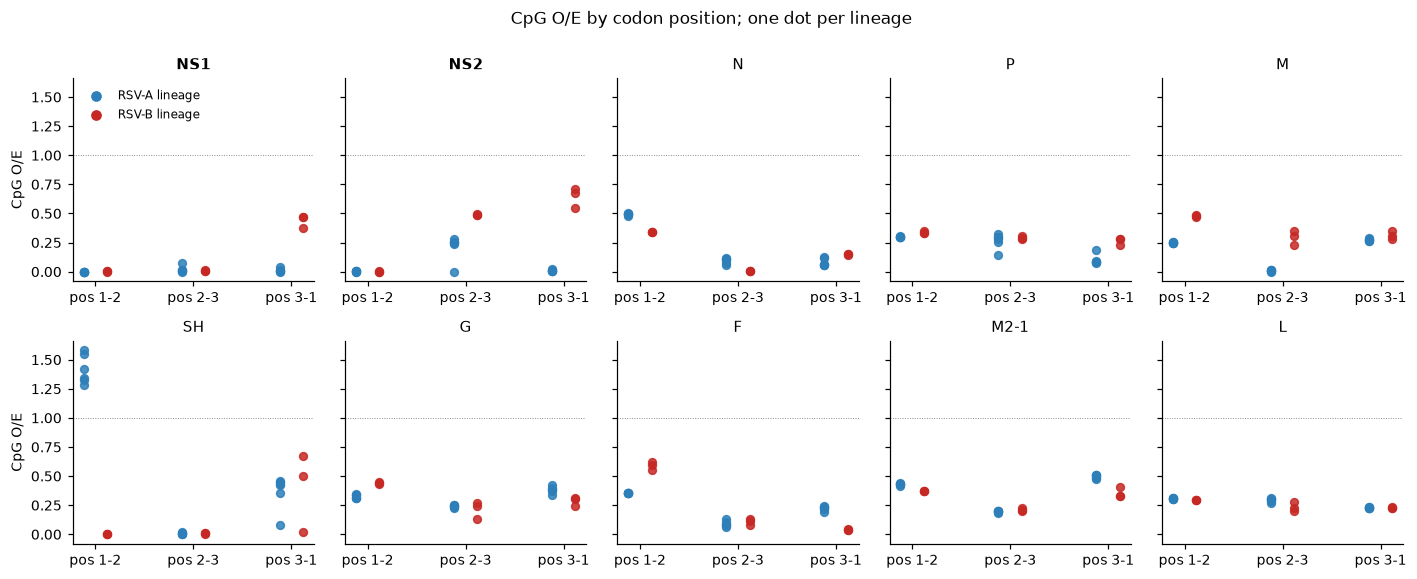

In [6]:
fig, axs = plt.subplots(2, 5, figsize=(13, 5.2), sharey=True)
for ax, g in zip(axs.flat, GENES):
    for j, c in enumerate(["12", "23", "31"]):
        for sub, off in (("A", -0.12), ("B", 0.12)):
            v = lin_tab[(lin_tab.gene == g) & (lin_tab.Subtype == sub)][f"oe{c}"]
            ax.scatter(np.full(len(v), j + off), v, s=26, color=PAL[sub], alpha=.85)
    ax.set_title(g, fontsize=10, fontweight="bold" if g in ("NS1", "NS2") else "normal")
    ax.set_xticks(range(3)); ax.set_xticklabels(["pos 1-2", "pos 2-3", "pos 3-1"])
    ax.axhline(1, color="grey", lw=.6, ls=":")
for ax in axs[:, 0]:
    ax.set_ylabel("CpG O/E")
axs[0, 0].scatter([], [], color=PAL["A"], label="RSV-A lineage"); axs[0, 0].scatter([], [], color=PAL["B"], label="RSV-B lineage")
axs[0, 0].legend(frameon=False, fontsize=8, loc="upper left")
fig.suptitle("CpG O/E by codon position; one dot per lineage", y=1.0)
plt.tight_layout()
fig.savefig("results/figures/fig7_cpg_by_codon_position.png", dpi=200, bbox_inches="tight")
plt.show()

In [7]:
print("CpG O/E, range across lineages (A | B)")
t = span("oe12").join(span("oe23"), lsuffix=" pos1-2", rsuffix=" pos2-3").join(span("oe31").add_suffix(" pos3-1"))
t

CpG O/E, range across lineages (A | B)


Subtype,A pos1-2,B pos1-2,A pos2-3,B pos2-3,A pos3-1,B pos3-1
gene,,,,,,
NS1,0.0-0.0,0.0-0.0,0.0-0.07,0.01-0.02,0.0-0.04,0.38-0.47
NS2,0.0-0.0,0.0-0.01,0.0-0.28,0.48-0.49,0.0-0.02,0.55-0.71
N,0.48-0.5,0.34-0.34,0.06-0.12,0.0-0.01,0.05-0.13,0.15-0.15
P,0.29-0.3,0.33-0.35,0.14-0.32,0.28-0.31,0.08-0.19,0.23-0.28
M,0.25-0.25,0.47-0.49,0.0-0.02,0.23-0.35,0.27-0.29,0.28-0.35
SH,1.28-1.58,0.0-0.0,0.0-0.02,0.01-0.01,0.08-0.46,0.02-0.67
G,0.31-0.35,0.43-0.45,0.22-0.26,0.13-0.27,0.34-0.42,0.25-0.31
F,0.35-0.36,0.55-0.63,0.06-0.14,0.08-0.13,0.2-0.24,0.04-0.04
M2-1,0.42-0.44,0.37-0.37,0.18-0.2,0.2-0.23,0.48-0.51,0.33-0.41


**Reading it (RSV-A lineages vs RSV-B lineages, ranges do not overlap unless stated).**

- **NS1:** the A-versus-B gap is entirely at **pos 3-1** (A 0.00-0.04, B 0.38-0.47). Pos 1-2 is 0 in both subtypes and pos 2-3 is near 0 in both, so those carry no A-versus-B difference.
- **NS2:** the gap is at **pos 2-3** (A 0.00-0.28, B 0.48-0.49) and **pos 3-1** (A 0.00-0.02, B 0.55-0.71). Both are positions where the third base is free to change without altering the protein. Pos 1-2 is about 0 in both.
- **Other genes:** M and P also have less CpG in A than B (the fold change in figure 6). M's gap is at **pos 2-3** (A 0.00-0.02, B 0.23-0.35), also a free position. N goes the other way at pos 2-3 (A 0.06-0.12, B 0.00-0.01) and SH differs at pos 1-2 (A 1.28-1.58, B 0.00), so no position class is simply "lower in A" across genes.

So the lost CpGs are where a synonymous change could remove them, which fits pressure acting on the RNA rather than the protein.

**RSV-A is not uniform.** In NS2, lineage A.D.1 has almost no CpG (O/E 0.004) while the other five A lineages sit near 0.1 (see 5.5), so the A-versus-B gap is not a single "A" value.

### Holding the amino acid fixed

The O/E above depends on base composition. A cleaner test keeps the **protein fixed**: look at codons that have a free choice of third base (some synonym ends in C and some does not), and ask how often they end in C **when the next amino acid is Gly/Ala/Val/Asp/Glu** (whose codons all start with G, so a C would make a CpG) **versus any other next amino acid**. If nothing suppresses CpG the two rates are equal and the ratio is 1.

In [8]:
jr = lin_tab.groupby(["gene", "Subtype"])[["c3_before_G", "c3_before_other", "junction_ratio"]].mean().round(3)
jr = jr.unstack().reindex(GENES)
jr

c3_before_G        c3_before_other        junction_ratio       
Subtype           A      B               A      B              A      B
gene                                                                   
NS1           0.002  0.065           0.239  0.174          0.010  0.377
NS2           0.003  0.216           0.339  0.375          0.008  0.576
N             0.016  0.031           0.274  0.278          0.057  0.111
P             0.024  0.082           0.287  0.367          0.083  0.224
M             0.078  0.077           0.350  0.308          0.223  0.250
SH            0.117  0.118           0.383  0.299          0.306  0.397
G             0.221  0.105           0.466  0.429          0.474  0.246
F             0.054  0.009           0.299  0.288          0.180  0.031
M2-1          0.116  0.082           0.308  0.330          0.376  0.248
L             0.039  0.039           0.199  0.204          0.194  0.189

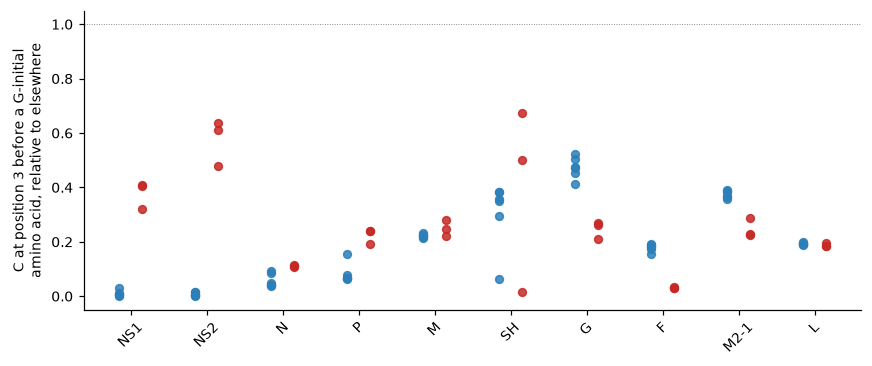

In [9]:
fig, ax = plt.subplots(figsize=(8, 3.4))
for i, g in enumerate(GENES):
    for sub, off in (("A", -0.15), ("B", 0.15)):
        v = lin_tab[(lin_tab.gene == g) & (lin_tab.Subtype == sub)]["junction_ratio"]
        ax.scatter(np.full(len(v), i + off), v, s=26, color=PAL[sub], alpha=.85)
ax.axhline(1, color="grey", lw=.6, ls=":")
ax.set_xticks(range(len(GENES))); ax.set_xticklabels(GENES, rotation=45)
ax.set_ylabel("C at position 3 before a G-initial\namino acid, relative to elsewhere")
plt.tight_layout()
fig.savefig("results/figures/fig8_junction_ratio.png", dpi=200, bbox_inches="tight")
plt.show()

**Reading it.** With the protein held fixed, RSV-A NS1 and NS2 almost never put a C at position 3 before a G-initial amino acid (ratio 0.01; for NS1, 0.2% of such codons end in C against 24% elsewhere). RSV-B does it at 0.38 (NS1) and 0.58 (NS2). The ratio is below 1 in nearly every gene of both subtypes (0.01-0.58), so junction CpG avoidance is general in RSV; what is special about NS1/NS2 of A is how complete it is. Two genes go the other way (F and G have a lower ratio in B than A), so A is not simply stricter everywhere.

---
## 5.4 Selection on the protein (HyPhy)

HyPhy's **SLAC** counts synonymous and non-synonymous changes along a tree and gives one gene-wide dN/dS (ω). Below 1 means the protein is being conserved. If A and B had very different ω in NS1/NS2 the CpG gap could be a protein story; if ω is alike, it is more likely a codon-choice story.

Each gene used 100 random genomes per subtype (50 + 50 for the joint "AB" tree), aligned at the protein level, tree by IQ-TREE (`scripts/run_hyphy.py`).

In [10]:
hy = pd.read_csv("results/hyphy_summary.tsv", sep="\t")
w = hy.pivot(index="gene", columns="Subtype", values="omega")
w = w.reindex([g for g in GENES if g in w.index])
cnt = hy[hy.Subtype != "AB"].assign(
    subs=lambda x: x.observed_S.astype(int).astype(str) + " S / " + x.observed_NS.astype(int).astype(str) + " N")
cnt = cnt.pivot(index="gene", columns="Subtype", values="subs").reindex(w.index)
w.round(3).add_prefix("omega ").join(cnt.add_prefix("changes "))

Subtype,omega A,omega AB,omega B,changes A,changes B
gene,,,,,
NS1,0.091,0.093,0.096,68 S / 14 N,53 S / 14 N
NS2,0.141,0.165,0.209,75 S / 24 N,79 S / 30 N
N,0.043,0.031,0.031,213 S / 19 N,174 S / 12 N
P,0.095,0.080,0.087,156 S / 32 N,154 S / 27 N
M,0.048,0.042,0.023,177 S / 22 N,160 S / 8 N
SH,0.201,0.253,0.285,30 S / 16 N,27 S / 17 N
F,0.094,0.078,0.115,373 S / 74 N,321 S / 79 N
M2-1,0.123,0.092,0.090,110 S / 25 N,109 S / 17 N


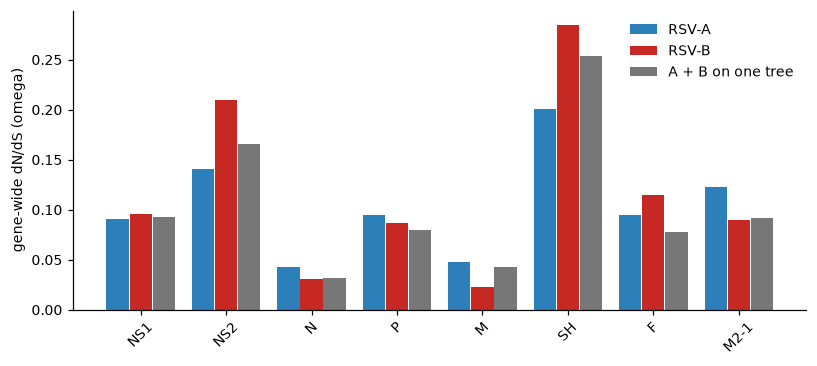

In [11]:
fig, ax = plt.subplots(figsize=(7.5, 3.4))
x = np.arange(len(w))
for k, (sub, c) in enumerate((("A", PAL["A"]), ("B", PAL["B"]), ("AB", "#777777"))):
    ax.bar(x + (k - 1) * 0.27, w[sub], 0.26, color=c, label={"AB": "A + B on one tree"}.get(sub, f"RSV-{sub}"))
ax.set_xticks(x); ax.set_xticklabels(w.index, rotation=45); ax.set_ylabel("gene-wide dN/dS (omega)")
ax.legend(frameon=False)
plt.tight_layout()
fig.savefig("results/figures/fig9_hyphy_omega.png", dpi=200, bbox_inches="tight")
plt.show()

**Reading it.** Every gene is under strong purifying selection (ω well below 1). NS1 has the same ω in A and B (0.091 vs 0.096), so the protein is conserved equally and the CpG gap is not explained by a difference in protein constraint. NS2 is slightly more relaxed in B (0.21 vs 0.14), but both are low.

**Limits.** Within a subtype the genomes are close relatives, so each gene shows only tens of changes (the "changes" columns). ω is therefore imprecise: fine for "both strongly purifying", not for small differences. SLAC pools the whole tree, so it cannot say *where on the tree* the CpG was lost.

---
## 5.5 Does NS1 CpG change over time inside a lineage?

From the trend analysis (`results/slopes_by_gene.tsv`), cluster-robust.

In [12]:
sl = pd.read_csv("results/slopes_by_gene.tsv", sep="\t")
ns = sl[(sl.gene.isin(["NS1", "NS2"])) & (sl.feature == "oe_CG")]
ns[["Subtype", "lineage_grp", "gene", "n", "mean", "slope", "p", "n_clusters"]].round(4).sort_values(["gene", "Subtype", "lineage_grp"])

,Subtype,lineage_grp,gene,n,mean,slope,p,n_clusters
13,A,A.D,NS1,1373,0.0122,0.0021,0.0022,14
33,A,A.D.1,NS1,5080,0.0100,0.0004,0.7399,12
53,A,A.D.2,NS1,630,0.0216,-0.0012,0.6495,4
73,A,A.D.3,NS1,4727,0.0172,0.0044,0.1069,12
93,A,A.D.4,NS1,368,0.0014,-0.0005,0.1400,10
113,A,A.D.5,NS1,3054,0.0274,0.0025,0.7142,4
133,B,B.D,NS1,342,0.1628,-0.0005,0.8552,11
153,B,B.D.4,NS1,4461,0.2010,-0.0003,0.8261,5
173,B,B.D.E,NS1,12407,0.2057,0.0060,0.1055,11
15,A,A.D,NS2,1373,0.0994,0.0019,0.0357,14


**Reading it.** The NS1 slopes are tiny (|slope| at most 0.006 per year) and not falling; only A.D NS1 is nominally significant, and it rises (+0.0021 per year from a mean of 0.012). NS2 has two nominal rises (A.D p = 0.036, A.D.2 p = 0.0055 on 4 clusters). Across these 18 tests, only A.D NS1 survives a Bonferroni correction (p 0.002 x 18 = 0.04). **No lineage is losing CpG in NS1/NS2 now**; the gap is a fixed difference between subtypes, not an ongoing trend.

---
## Summary

| Question | Answer |
|---|---|
| Any non-human host? | **No.** All 33,040 genomes are `Human`. |
| Where is the NS1/NS2 CpG missing in RSV-A? | At **synonymous positions**: the codon junction (pos 3-1) in NS1; junction and pos 2-3 in NS2. Pos 1-2, where the amino acid decides, is empty in both subtypes. |
| Is it the protein? | **Unlikely.** NS1 ω is 0.091 (A) vs 0.096 (B); with the amino acid held fixed, A almost never uses a C before a G-initial residue (ratio 0.01 vs 0.38). |
| Still changing? | **No.** No lineage shows falling NS1/NS2 CpG. |

**What this does not show.** It is consistent with selection against CpG at the RNA level (a ZAP-like pressure), but it does not prove it: a mutation-bias or ancestral-codon-usage explanation would look the same in a snapshot. Testing it needs the tree (when did the loss happen, and was it a burst of CpG-removing synonymous changes on one branch). The lineage-balanced sample (250 per lineage) also means counts are per lineage, with 6 A against 3 B.

**Next:** HyPhy cannot place the CpG loss on the tree by itself; an ancestral reconstruction on a joint A+B NS1/NS2 tree and a count of CpG-creating versus CpG-destroying synonymous changes per branch would.